In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

sns.set_style("whitegrid")
RANDOM_STATE = 42

In [2]:

from google.colab import files
uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])



Saving ai4i2020.csv to ai4i2020.csv


In [3]:

df.columns = (df.columns.str.replace(r"\s*\[.*?\]", "", regex=True)
                        .str.strip().str.replace(" ", "_"))
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (10000, 14)
Columns: ['UDI', 'Product_ID', 'Type', 'Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Machine_failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product_ID,Type,Air_temperature,Process_temperature,Rotational_speed,Torque,Tool_wear,Machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.info()
print("\nTarget variable: Machine_failure")
print(df["Machine_failure"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UDI                  10000 non-null  int64  
 1   Product_ID           10000 non-null  object 
 2   Type                 10000 non-null  object 
 3   Air_temperature      10000 non-null  float64
 4   Process_temperature  10000 non-null  float64
 5   Rotational_speed     10000 non-null  int64  
 6   Torque               10000 non-null  float64
 7   Tool_wear            10000 non-null  int64  
 8   Machine_failure      10000 non-null  int64  
 9   TWF                  10000 non-null  int64  
 10  HDF                  10000 non-null  int64  
 11  PWF                  10000 non-null  int64  
 12  OSF                  10000 non-null  int64  
 13  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB

Target variable: Machine_fail

In [5]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Product IDs:", df["Product_ID"].duplicated().sum())
df.describe().T

Missing values:
 UDI                    0
Product_ID             0
Type                   0
Air_temperature        0
Process_temperature    0
Rotational_speed       0
Torque                 0
Tool_wear              0
Machine_failure        0
TWF                    0
HDF                    0
PWF                    0
OSF                    0
RNF                    0
dtype: int64

Duplicate rows: 0
Duplicate Product IDs: 0


,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air_temperature,10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process_temperature,10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational_speed,10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque,10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool_wear,10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine_failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


Non-failed machines: 9661  |  Failed machines: 339
Failure rate: 3.39%


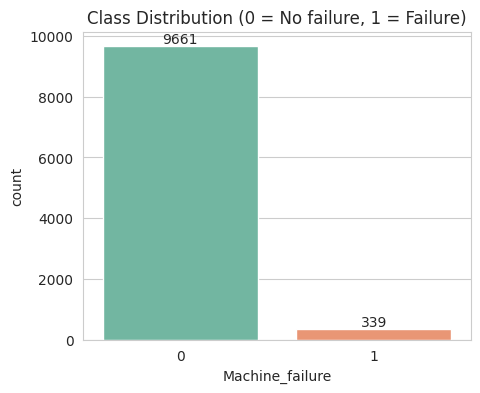

In [6]:
counts = df["Machine_failure"].value_counts()
print(f"Non-failed machines: {counts[0]}  |  Failed machines: {counts[1]}")
print(f"Failure rate: {counts[1]/len(df)*100:.2f}%")

plt.figure(figsize=(5,4))
ax = sns.countplot(x="Machine_failure", data=df, palette="Set2")
for c in ax.containers: ax.bar_label(c)
plt.title("Class Distribution (0 = No failure, 1 = Failure)")
plt.show()

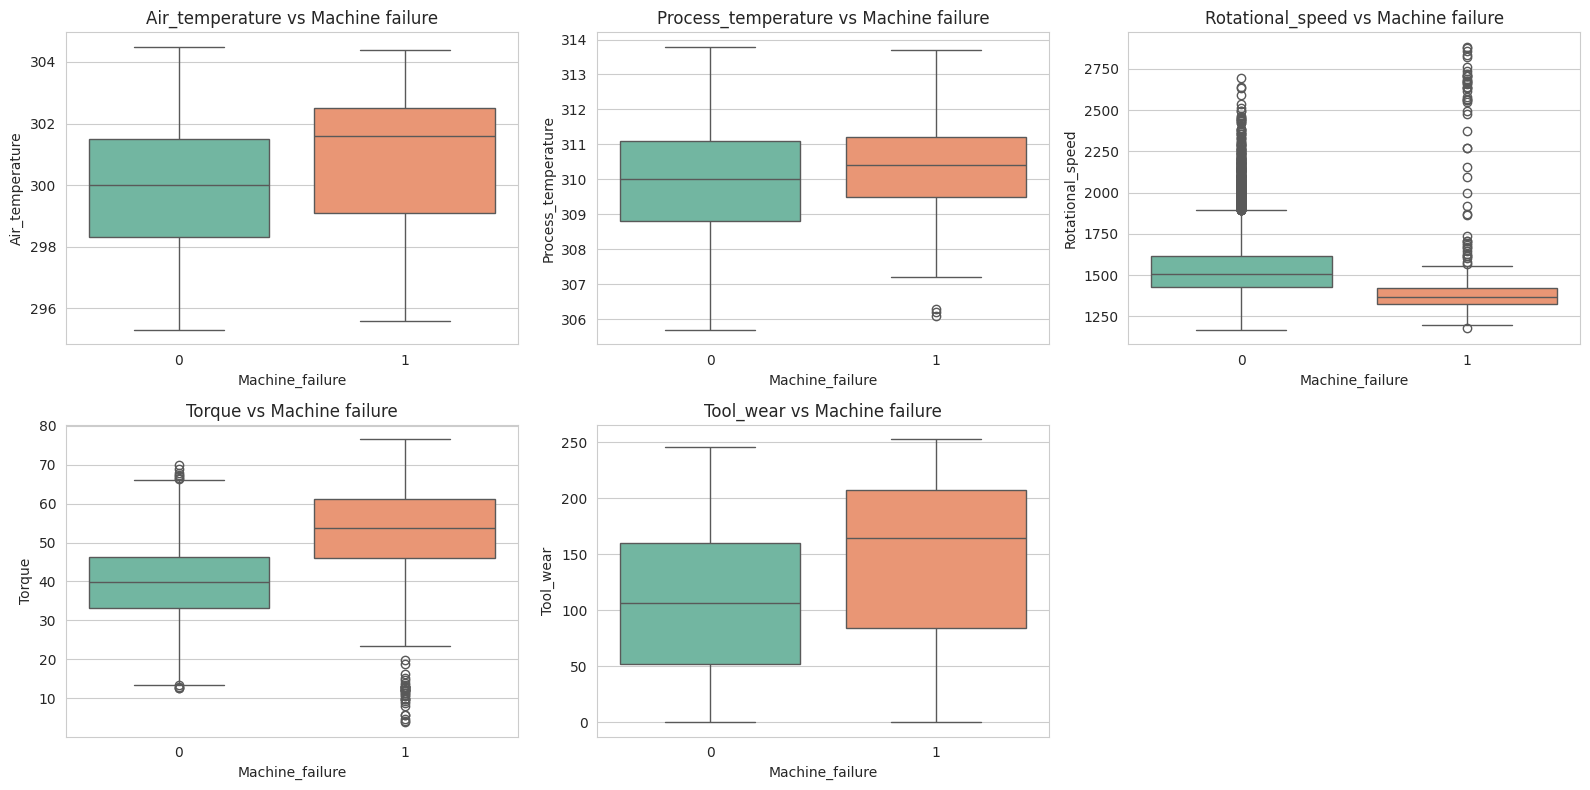

In [7]:
num_cols = ["Air_temperature","Process_temperature","Rotational_speed","Torque","Tool_wear"]

fig, axes = plt.subplots(2, 3, figsize=(16,8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x="Machine_failure", y=col, data=df, palette="Set2", ax=ax)
    ax.set_title(f"{col} vs Machine failure")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

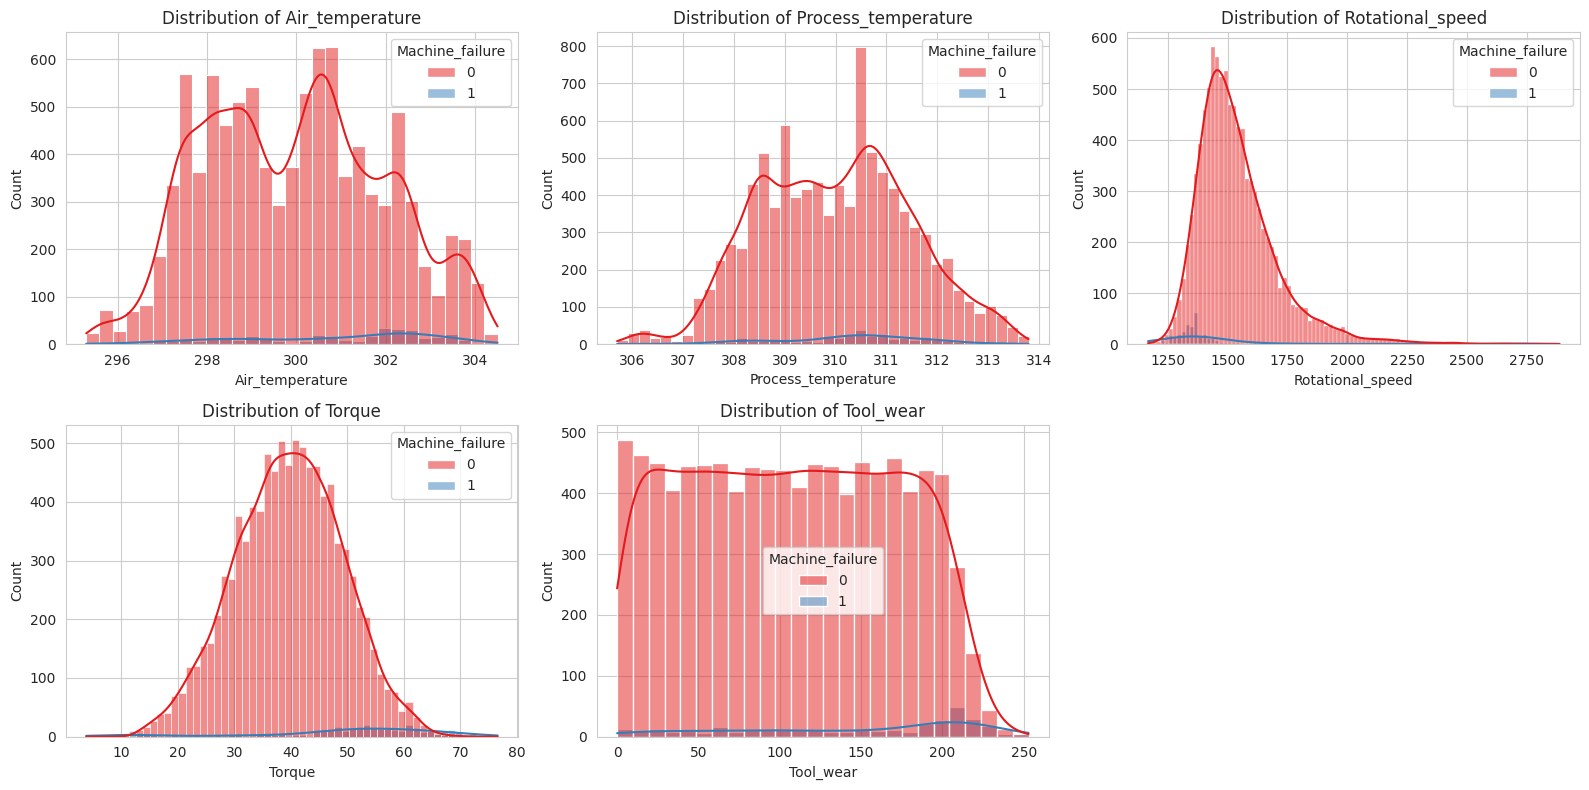

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16,8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="Machine_failure", kde=True, ax=ax, palette="Set1")
    ax.set_title(f"Distribution of {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

Type
H    2.09
L    3.92
M    2.77
Name: Machine_failure, dtype: float64


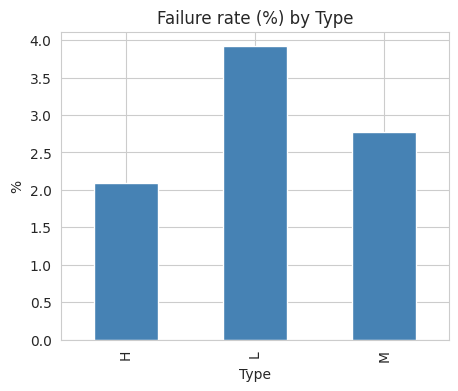

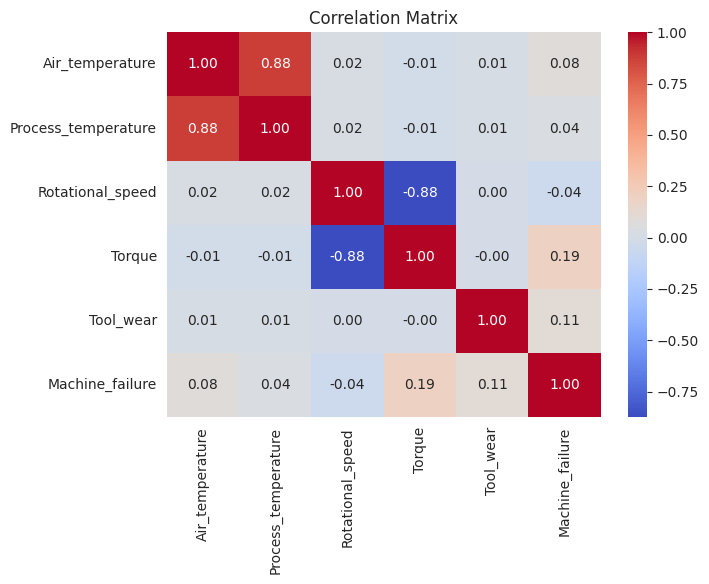

In [9]:
# failure rate by machine Type
rate = df.groupby("Type")["Machine_failure"].mean() * 100
print(rate.round(2))
rate.plot(kind="bar", color="steelblue", figsize=(5,4), title="Failure rate (%) by Type")
plt.ylabel("%"); plt.show()

# correlation heatmap
plt.figure(figsize=(7,5))
sns.heatmap(df[num_cols + ["Machine_failure"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix"); plt.show()

In [10]:

leak_cols = ["TWF","HDF","PWF","OSF","RNF"]
id_cols   = [c for c in ["UDI","Product_ID"] if c in df.columns]

X = df.drop(columns=["Machine_failure"] + leak_cols + id_cols)
y = df["Machine_failure"]

num_features = ["Air_temperature","Process_temperature","Rotational_speed","Torque","Tool_wear"]
cat_features = ["Type"]

print("Features used:", list(X.columns))

# encode categorical + scale numeric inside one preprocessing step
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

Features used: ['Type', 'Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear']


##  Train / test split (80 / 20, stratified)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train failure rate: %.2f%%" % (y_train.mean()*100))
print("Test  failure rate: %.2f%%" % (y_test.mean()*100))

Train: (8000, 6)  Test: (2000, 6)
Train failure rate: 3.39%
Test  failure rate: 3.40%


In [12]:
def make_pipe(clf):
    return Pipeline([("prep", preprocessor), ("clf", clf)])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Decision Tree":       make_pipe(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest":       make_pipe(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.


In [13]:
def evaluate(model, X_t, y_t):
    pred = model.predict(X_t)
    return {
        "Accuracy":  accuracy_score(y_t, pred),
        "Precision": precision_score(y_t, pred, zero_division=0),
        "Recall":    recall_score(y_t, pred),
        "F1-score":  f1_score(y_t, pred),
        "ROC-AUC":   roc_auc_score(y_t, model.predict_proba(X_t)[:,1]),
    }

results = {name: evaluate(m, X_test, y_test) for name, m in models.items()}
comparison = pd.DataFrame(results).T.round(4)
print("Precision / Recall / F1 are for the FAILURE class (1)")
comparison

Precision / Recall / F1 are for the FAILURE class (1)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070
Decision Tree,0.9775,0.6949,0.6029,0.6457,0.7968
Random Forest,0.9800,0.9667,0.4265,0.5918,0.9635


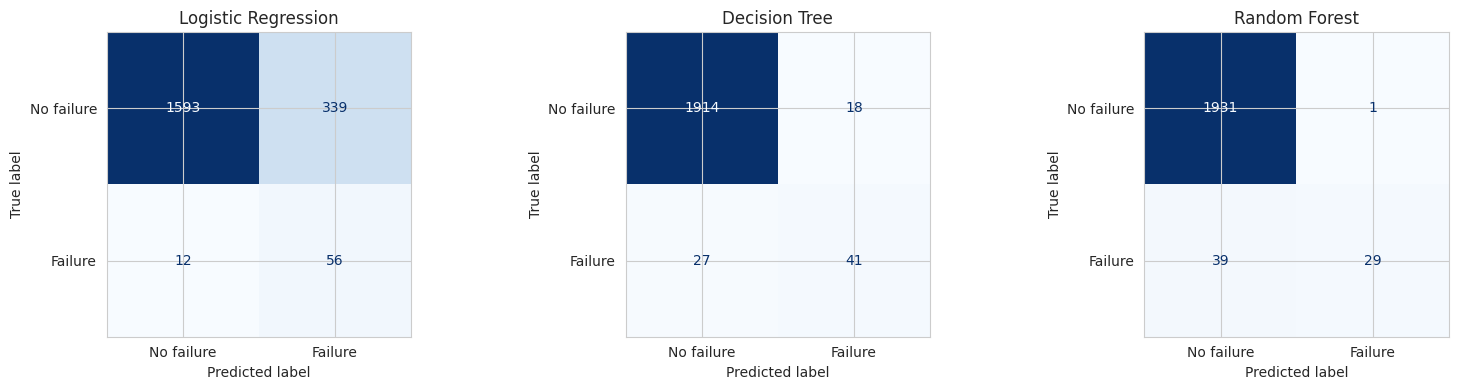


===== Logistic Regression =====
              precision    recall  f1-score   support

  No failure       0.99      0.82      0.90      1932
     Failure       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000


===== Decision Tree =====
              precision    recall  f1-score   support

  No failure       0.99      0.99      0.99      1932
     Failure       0.69      0.60      0.65        68

    accuracy                           0.98      2000
   macro avg       0.84      0.80      0.82      2000
weighted avg       0.98      0.98      0.98      2000


===== Random Forest =====
              precision    recall  f1-score   support

  No failure       0.98      1.00      0.99      1932
     Failure       0.97      0.43      0.59        68

    accuracy                           0.98      2000
   macro avg       0.97      0.71      0.

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["No failure","Failure"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

for name, m in models.items():
    print(f"\n===== {name} =====")
    print(classification_report(y_test, m.predict(X_test), target_names=["No failure","Failure"]))

In [15]:
#
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {}
for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=skf, scoring="f1", n_jobs=-1)
    cv_rows[name] = list(scores) + [scores.mean(), scores.std()]
    print(f"{name}: {np.round(scores,4)}  | mean F1 = {scores.mean():.4f}")

cv_df = pd.DataFrame(cv_rows, index=[f"Fold {i}" for i in range(1,6)] + ["Mean","Std"]).T.round(4)
cv_df

Logistic Regression: [0.2474 0.2196 0.231  0.2439 0.231 ]  | mean F1 = 0.2346
Decision Tree: [0.6538 0.5393 0.6392 0.6296 0.617 ]  | mean F1 = 0.6158
Random Forest: [0.5974 0.5067 0.5455 0.525  0.4737]  | mean F1 = 0.5296


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Logistic Regression,0.2474,0.2196,0.2310,0.2439,0.2310,0.2346,0.0100
Decision Tree,0.6538,0.5393,0.6392,0.6296,0.6170,0.6158,0.0401
Random Forest,0.5974,0.5067,0.5455,0.5250,0.4737,0.5296,0.0413


## Hyperparameter tuning with GridSearchCV (scoring = F1)

In [16]:
param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1, 10, 100],
        "clf__class_weight": [None, "balanced"],
    },
    "Decision Tree": {
        "clf__max_depth": [3, 5, 8, 12, None],
        "clf__min_samples_split": [2, 10, 20],
        "clf__criterion": ["gini", "entropy"],
        "clf__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [8, 12, None],
        "clf__min_samples_split": [2, 5],
        "clf__class_weight": [None, "balanced"],
    },
}

tuned = {}
for name, model in models.items():
    print(f"Tuning {name} ...")
    gs = GridSearchCV(model, param_grids[name], cv=skf, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print("  Best params  :", gs.best_params_)
    print(f"  Best CV F1   : {gs.best_score_:.4f}\n")

Tuning Logistic Regression ...
  Best params  : {'clf__C': 10, 'clf__class_weight': None}
  Best CV F1   : 0.3304

Tuning Decision Tree ...
  Best params  : {'clf__class_weight': None, 'clf__criterion': 'gini', 'clf__max_depth': 12, 'clf__min_samples_split': 20}
  Best CV F1   : 0.7186

Tuning Random Forest ...
  Best params  : {'clf__class_weight': None, 'clf__max_depth': None, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}
  Best CV F1   : 0.6320



In [17]:
summary = pd.DataFrame({
    "Best CV F1": {n: g.best_score_ for n, g in tuned.items()},
    "Test F1":    {n: f1_score(y_test, g.best_estimator_.predict(X_test)) for n, g in tuned.items()},
    "Test Recall":{n: recall_score(y_test, g.best_estimator_.predict(X_test)) for n, g in tuned.items()},
    "Test Precision":{n: precision_score(y_test, g.best_estimator_.predict(X_test), zero_division=0) for n, g in tuned.items()},
}).round(4)
display(summary)

best_name = summary["Best CV F1"].idxmax()
best_model = tuned[best_name].best_estimator_
print(f"\n>>> Selected model: {best_name}")

,Best CV F1,Test F1,Test Recall,Test Precision
Logistic Regression,0.3304,0.1975,0.1176,0.6154
Decision Tree,0.7186,0.7591,0.7647,0.7536
Random Forest,0.6320,0.6481,0.5147,0.8750



>>> Selected model: Decision Tree


Final test metrics:
  Accuracy  : 0.9835
  Precision : 0.7536
  Recall    : 0.7647
  F1-score  : 0.7591
  ROC-AUC   : 0.9074

               precision    recall  f1-score   support

  No failure       0.99      0.99      0.99      1932
     Failure       0.75      0.76      0.76        68

    accuracy                           0.98      2000
   macro avg       0.87      0.88      0.88      2000
weighted avg       0.98      0.98      0.98      2000



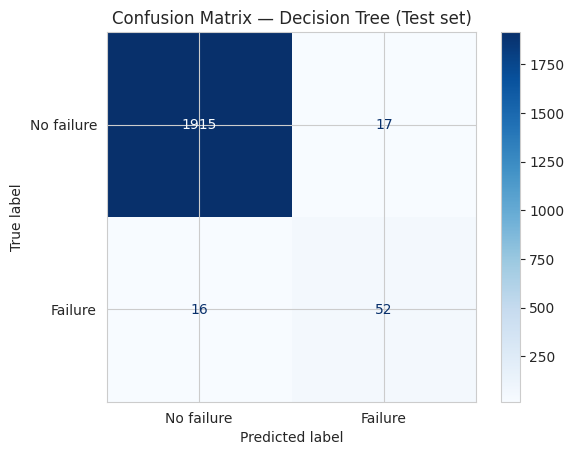

In [18]:
final = evaluate(best_model, X_test, y_test)
print("Final test metrics:")
for k, v in final.items(): print(f"  {k:10s}: {v:.4f}")

print("\n", classification_report(y_test, best_model.predict(X_test), target_names=["No failure","Failure"]))

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test,
        display_labels=["No failure","Failure"], cmap="Blues")
plt.title(f"Confusion Matrix — {best_name} (Test set)")
plt.show()

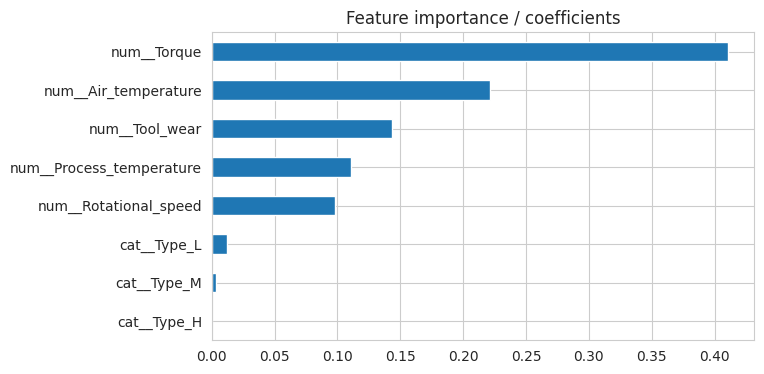

In [19]:
# feature importance (if the selected model supports it)
clf = best_model.named_steps["clf"]
feat_names = best_model.named_steps["prep"].get_feature_names_out()
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=feat_names).sort_values()
elif hasattr(clf, "coef_"):
    imp = pd.Series(clf.coef_[0], index=feat_names).sort_values()
else:
    imp = None
if imp is not None:
    imp.plot(kind="barh", figsize=(7,4), title="Feature importance / coefficients")
    plt.show()

In [20]:
joblib.dump(best_model, "machine_failure_model.joblib")
print("Saved: machine_failure_model.joblib")

from google.colab import files
files.download("machine_failure_model.joblib")

Saved: machine_failure_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

model = joblib.load("machine_failure_model.joblib")

def predict_failure(machine_type, air_temp, process_temp, rpm, torque, tool_wear):
    new = pd.DataFrame([{
        "Type": machine_type,
        "Air_temperature": air_temp,
        "Process_temperature": process_temp,
        "Rotational_speed": rpm,
        "Torque": torque,
        "Tool_wear": tool_wear,
    }])
    pred = model.predict(new)[0]
    prob = model.predict_proba(new)[0][1]
    return pred, prob


pred, prob = predict_failure("M", 300, 310, 1500, 40, 100)
print("Machine Failure:", "Yes" if pred == 1 else "No")
print(f"Estimated failure probability: {prob*100:.2f}%")

Machine Failure: No
Estimated failure probability: 0.00%


In [22]:

print("=== Machine Failure Prediction System ===")
m_type  = input("Machine Type (Low performance(L) / Mediam performance (M) / High performance (H)): ").strip().upper()
air     = float(input("Air temperature [K] (e.g. 300): "))
proc    = float(input("Process temperature [K] (e.g. 310): "))
rpm     = float(input("Rotational speed [rpm] (e.g. 1500): "))
torque  = float(input("Torque [Nm] (e.g. 40): "))
wear    = float(input("Tool wear [min] (e.g. 100): "))

pred, prob = predict_failure(m_type, air, proc, rpm, torque, wear)
print("\nMachine Failure:", "Yes" if pred == 1 else "No")
print(f"Estimated failure probability: {prob*100:.2f}%")

=== Machine Failure Prediction System ===
Machine Type (Low performance(L) / Mediam performance (M) / High performance (H)): H
Air temperature [K] (e.g. 300): 100
Process temperature [K] (e.g. 310): 50
Rotational speed [rpm] (e.g. 1500): 24
Torque [Nm] (e.g. 40): 40
Tool wear [min] (e.g. 100): 85

Machine Failure: No
Estimated failure probability: 0.00%
